### Name:Riya Waghmare
### Roll no:35
### Class:B-B3


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans,AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score)

from scipy.cluster.hierarchy import linkage,dendrogram

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize']=(8,6)

df=pd.read_csv("Wholesale customers data - Wholesale customers data.csv")

In [ ]:
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [ ]:
df.tail()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
435,1,3,29703,12051,16027,13135,182,2204
436,1,3,39228,1431,764,4510,93,2346
437,2,3,14531,15488,30243,437,14841,1867
438,1,3,10290,1981,2232,1038,168,2125
439,1,3,2787,1698,2510,65,477,52


In [ ]:
df.shape

(440, 8)

In [ ]:
df.columns

Index(['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen',
       'Detergents_Paper', 'Delicassen'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [ ]:
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [ ]:
df.isnull().sum()

,0
Channel,0
Region,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.dtypes

,0
Channel,int64
Region,int64
Fresh,int64
Milk,int64
Grocery,int64
Frozen,int64
Detergents_Paper,int64
Delicassen,int64


In [ ]:

X = df.drop(columns=['Channel', 'Region'])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [ ]:
import pandas as pd

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=X.columns,
    index=X.index
)

X_scaled_df.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339
1,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151
2,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293
3,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411
4,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347


In [ ]:
display( X_scaled_df.head())

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339
1,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151
2,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293
3,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411
4,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347


In [ ]:
print(X_scaled_df.mean().round())

Fresh              -0.0
Milk                0.0
Grocery            -0.0
Frozen              0.0
Detergents_Paper    0.0
Delicassen         -0.0
dtype: float64


In [ ]:
print("\n Scaled feature sd ")
print(X_scaled_df.std(ddof=0).round(3))


 Scaled feature sd 
Fresh               1.0
Milk                1.0
Grocery             1.0
Frozen              1.0
Detergents_Paper    1.0
Delicassen          1.0
dtype: float64


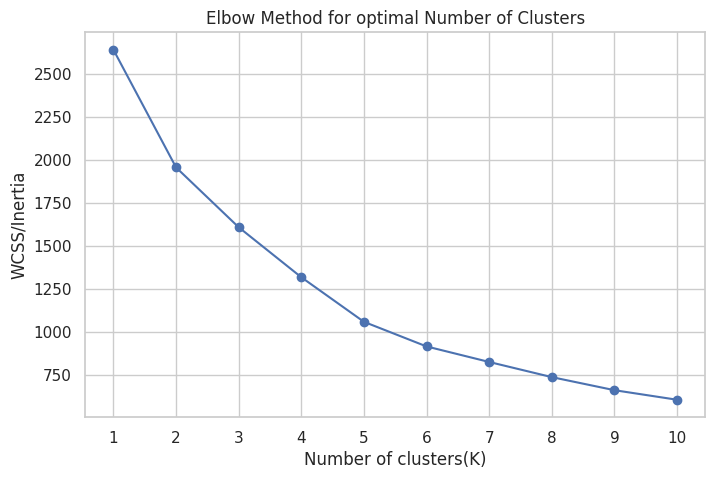

In [ ]:
wccs=[]
k_values=range(1,11)
for k in k_values:
    kmeans=KMeans(n_clusters=k,random_state=42,n_init=10)
    kmeans.fit(X_scaled_df)
    wccs.append(kmeans.inertia_)
plt.figure(figsize=(8,5))
plt.plot(list(k_values),wccs,marker="o")
plt.xlabel("Number of clusters(K)")
plt.ylabel("WCSS/Inertia")
plt.title("Elbow Method for optimal Number of Clusters")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [ ]:
silhouette_values = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled_df)
    score = silhouette_score(X_scaled_df, labels)
    silhouette_values.append(score)
silhouette_table = pd.DataFrame({
    "Number of Clusters": list(range(2, 11)),
    "Silhouette Score": silhouette_values
})
display(silhouette_table.round(4))

,Number of Clusters,Silhouette Score
0,2,0.5472
1,3,0.5483
2,4,0.3485
3,5,0.3690
4,6,0.3782
5,7,0.3343
6,8,0.3201
7,9,0.3090
8,10,0.3112


In [ ]:
suggested_k=int(
    silhouette_table.loc[silhouette_table["Silhouette Score"].idxmax(),"Number of Clusters"]
)
print("K suggested by the highest silhouette score:",suggested_k)

K suggested by the highest silhouette score: 3


In [ ]:
K=suggested_k
kmeans_model=KMeans(n_clusters=K,random_state=42,n_init=10)
kmean_labels=kmeans_model.fit(X_scaled_df)

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmean_labels = kmeans.fit_predict(X_scaled_df)
df_kmeans = df.copy()
df_kmeans["KMeans_Cluster"] = kmean_labels
print("K-Means clustering complete!")
print("\nNumber of customers in each cluster:")
print(df_kmeans["KMeans_Cluster"].value_counts().sort_index())
print("\nSample records with cluster labels:")
display(df_kmeans.head())

K-Means clustering complete!

Number of customers in each cluster:
KMeans_Cluster
0     45
1    393
2      2
Name: count, dtype: int64

Sample records with cluster labels:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,KMeans_Cluster
0,2,3,12669,9656,7561,214,2674,1338,1
1,2,3,7057,9810,9568,1762,3293,1776,1
2,2,3,6353,8808,7684,2405,3516,7844,1
3,1,3,13265,1196,4221,6404,507,1788,1
4,2,3,22615,5410,7198,3915,1777,5185,1


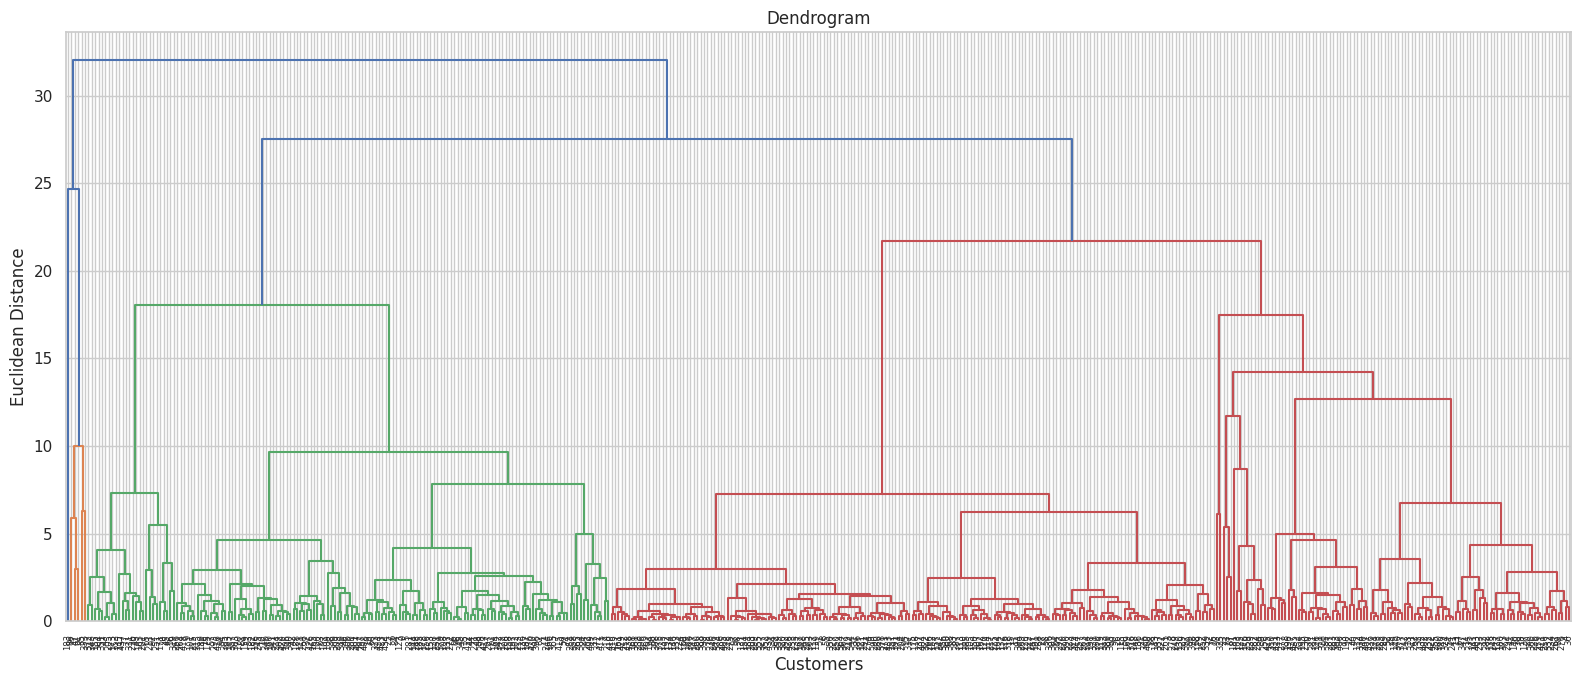

In [ ]:
Z=linkage(X_scaled_df,method="ward",metric="euclidean")
plt.figure(figsize=(16,7))
dendrogram(Z,leaf_rotation=90,leaf_font_size=6)
plt.title("Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Euclidean Distance")
plt.tight_layout()
plt.show()

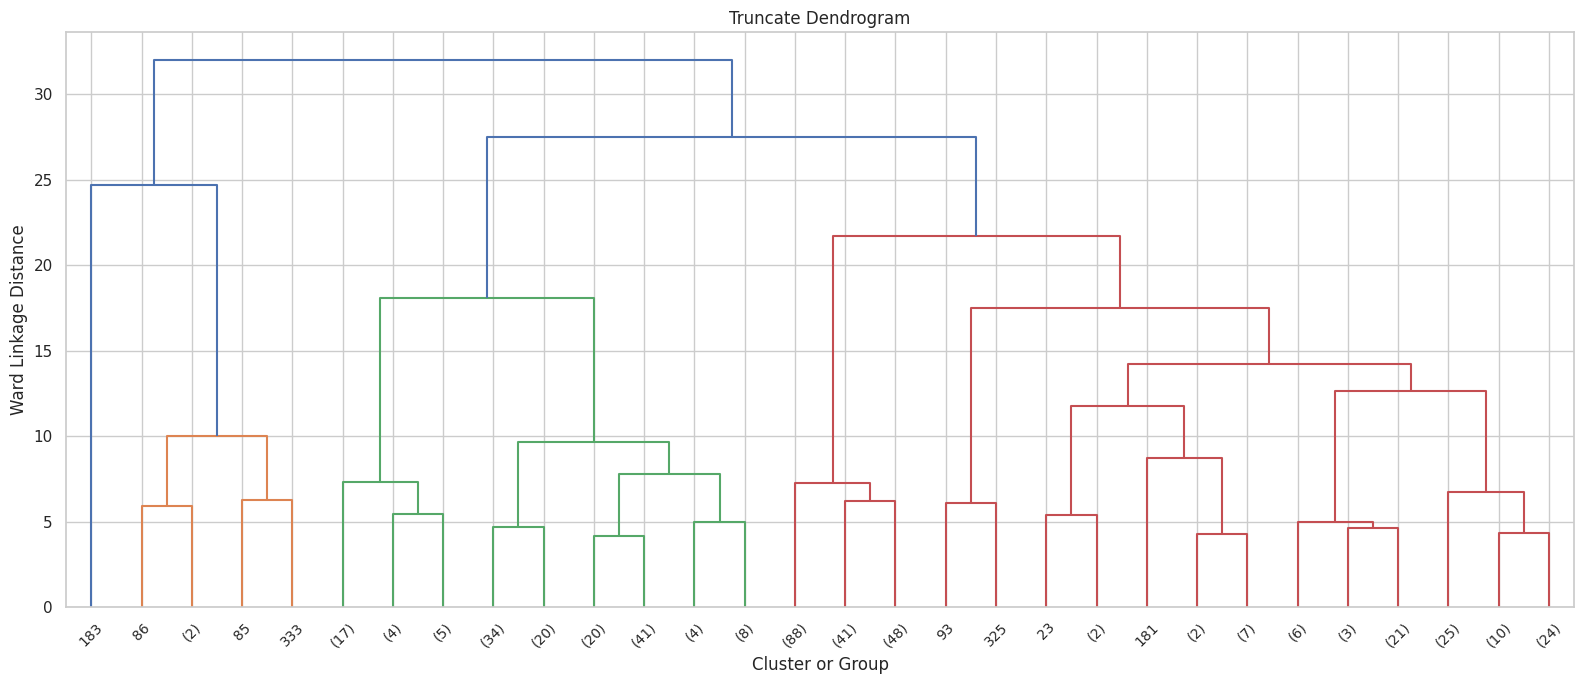

In [ ]:
plt.figure(figsize=(16,7))
dendrogram(Z,truncate_mode="lastp",p=30,show_leaf_counts=True,leaf_rotation=45)
plt.title("Truncate Dendrogram")
plt.xlabel("Cluster or Group")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.show()

In [ ]:
pca=PCA(n_components=2)
X_pca=pca.fit_transform(X_scaled_df)
print(
    "Variance exlained by two PCA coponent:",
    round(pca.explained_variance_ratio_.sum()*100,2),
    "%"
)
plot_df=pd.DataFrame({"PC1": X_pca[:,0],"PC2": X_pca[:,1],
                      "KMeans_Cluster":kmean_labels.astype(str)})

Variance exlained by two PCA coponent: 72.46 %


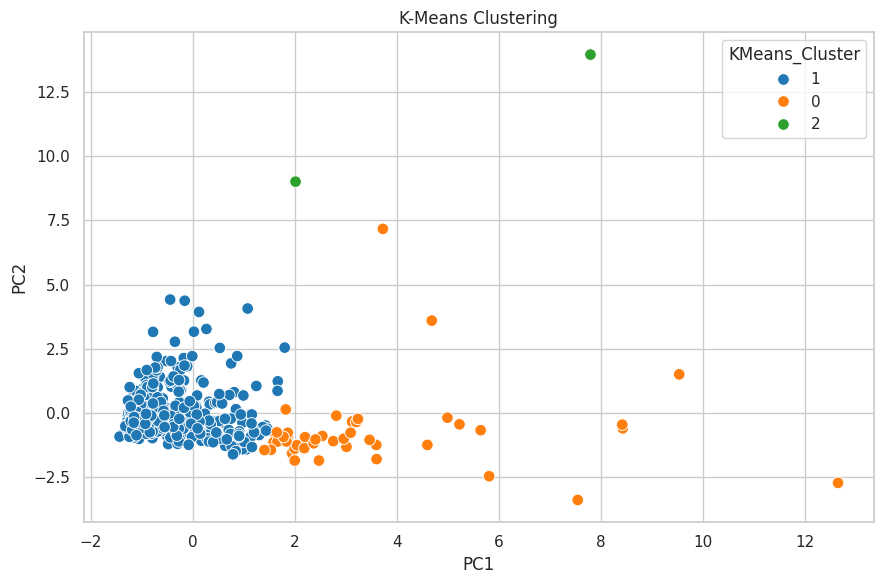

In [ ]:
plt.figure(figsize=(9,6))
sns.scatterplot(data=plot_df,x="PC1",y="PC2",hue="KMeans_Cluster",palette="tab10",s=70)
plt.title("K-Means Clustering")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.tight_layout()
plt.show()

In [ ]:
def evaluate_clustering(X_data,labels,model_name):
  return{
      "Algorithm":model_name,
      "Number Of Clusters":len(np.unique(labels)),
      "Silhouette Score":silhouette_score(X_data,labels)
  }

In [ ]:

hierarchical_model = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
hierarchical_labels = hierarchical_model.fit_predict(X_scaled_df)

comparision = pd.DataFrame([
    evaluate_clustering(X_scaled_df, kmean_labels, "K-Means"),
    evaluate_clustering(X_scaled_df, hierarchical_labels, "Hierarchical Clustering")
])

display(comparision.round(4))

,Algorithm,Number Of Clusters,Silhouette Score
0,K-Means,3,0.5483
1,Hierarchical Clustering,3,0.2646


In [ ]:
cluster_sizes=pd.DataFrame({
    "K-Means":pd.Series(kmean_labels).value_counts().sort_index(),
    "Hierarchical":pd.Series(hierarchical_labels).value_counts().sort_index()
})
display(cluster_sizes)

,K-Means,Hierarchical
0,45,6
1,393,281
2,2,153


In [ ]:
features = list(X_scaled_df.columns)
kmeans_profile=df[features].copy()
kmeans_profile["Cluster"]=kmean_labels
kmeans_means=kmeans_profile.groupby("Cluster").mean()
display(kmeans_means)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,10440.933333,19386.422222,28656.088889,2190.244444,13327.800000,2374.200000
1,12062.913486,4115.099237,5534.966921,2940.676845,1696.170483,1299.114504
2,34782.000000,30367.000000,16898.000000,48701.500000,755.500000,26776.000000
